# Homopolymer Graph

This notebook calculates the partition coefficient $K$ for a polymer in a slit-like pore and plots the six curves shown in the reference figure. The horizontal axis is $g=R_G/R_P$, and the curves use interaction values $\lambda=50, 3, 0.1, 0, -0.1, -3$.

The equation used here is

$$K(g,\lambda)=\sum_{m\text{ odd}} \frac{2\lambda^2}{\alpha_m^2(\lambda^2+\alpha_m^2+\lambda)}e^{-\alpha_m^2g^2}$$

Run the code cells from top to bottom to generate `reproduced_graph.png` with each curve labeled by its $\lambda$ value.

## Parameters

- $R_G$: radius of gyration of the polymer
- $R_P$: mean pore radius
- $g=R_G/R_P$: polymer size relative to the pore
- $\lambda$: adsorption interaction parameter

Negative $\lambda$ means attraction to the pore wall. Positive $\lambda$ means repulsion. At $\lambda=0$, the model gives $K=1$.

The infinite sum is truncated after the first 51 odd values of $m$.

In [1]:
import math

import matplotlib.pyplot as plt

## Finding the roots

The equation for $\alpha_m$ does not have a simple closed-form solution, so I find each root numerically. The bisection method starts with an interval containing the root and keeps cutting that interval in half.

In [2]:
def bisect(function, lower, upper, tolerance=1e-12):
    """Find a zero of a continuous function between lower and upper."""
    lower_value = function(lower)
    upper_value = function(upper)
    if lower_value * upper_value > 0:
        raise ValueError("The root is not bracketed.")

    while upper - lower > tolerance:
        middle = (lower + upper) / 2
        middle_value = function(middle)
        if lower_value * middle_value <= 0:
            upper, upper_value = middle, middle_value
        else:
            lower, lower_value = middle, middle_value
    return (lower + upper) / 2

## Characteristic roots

The roots satisfy

$$\alpha_m=\tan^{-1}\left(\frac{\lambda}{\alpha_m}\right)+\frac{(m-1)\pi}{2}.$$

For negative $\lambda$, the first root is imaginary. I handle it with the real variable $\beta$, using $\alpha_1^2=-\beta^2$ and $\beta\tanh(\beta)=-\lambda$.

In [3]:
def root_squared(lambda_value, odd_m):
    """Return alpha_m squared."""
    if odd_m == 1 and lambda_value == 0:
        return 0.0

    if odd_m == 1 and lambda_value < 0:
        beta = bisect(
            lambda beta: beta * math.tanh(beta) + lambda_value,
            1e-12,
            math.sqrt(-lambda_value) + 2,
        )
        return -(beta**2)

    base = (odd_m - 1) * math.pi / 2
    angle = math.pi / 2
    if lambda_value > 0:
        lower = base + 1e-10
        upper = base + angle - 1e-10
    else:
        lower = base - angle + 1e-10
        upper = base - 1e-10

    def characteristic_root(alpha):
        return alpha - base - math.atan(lambda_value / alpha)

    alpha = bisect(characteristic_root, lower, upper)
    return alpha**2

In [7]:
def K_homopolymer(g, lambda_value, terms=101):
    """Calculate the homopolymer partition coefficient K."""
    if lambda_value == 0:
        return 1.0

    total = 0.0
    for odd_m in range(1, terms + 1, 2):
        alpha_squared = root_squared(lambda_value, odd_m)
        denominator = alpha_squared * (
            lambda_value**2 + alpha_squared + lambda_value
        )
        term = 2 * lambda_value**2 / denominator
        total += term * math.exp(-alpha_squared * g**2)
    return total

## Plotting

For each value of $\lambda$, I calculate $K$ at 501 values of $g$ and plot the resulting points. The figure is also saved as `reproduced_graph.png`.

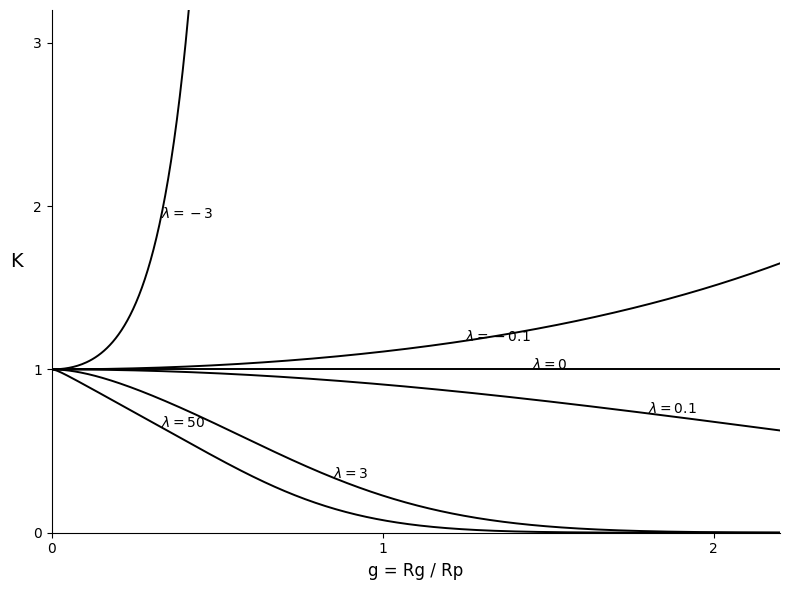

In [8]:
g_values = [index * 2.2 / 500 for index in range(501)]
lambda_values = [50, 3, 0.1, 0, -0.1, -3]

fig, ax = plt.subplots(figsize=(8, 6))
label_positions = {50: 0.33, 3: 0.85, 0.1: 1.8, 0: 1.45, -0.1: 1.25, -3: 0.33}
for lambda_value in lambda_values:
    k_values = [K_homopolymer(g, lambda_value) for g in g_values]
    ax.plot(g_values, k_values, color="black", linewidth=1.4)

    label_g = label_positions[lambda_value]
    label_k = K_homopolymer(label_g, lambda_value)
    if 0.05 < label_k < 3.05:
        ax.text(label_g, label_k, rf"$\lambda={lambda_value:g}$", fontsize=10)

ax.set_xlim(0, 2.2)
ax.set_ylim(0, 3.2)
ax.set_xlabel("g = Rg / Rp", fontsize=12)
ax.set_ylabel("K", fontsize=14, rotation=0, labelpad=12)
ax.set_xticks([0, 1, 2])
ax.set_yticks([0, 1, 2, 3])
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_position(("data", 0))
ax.spines["bottom"].set_position(("data", 0))
ax.grid(False)
fig.tight_layout()
fig.savefig("reproduced_graph.png", dpi=200, bbox_inches="tight")
plt.show()

## What the curves show

All curves start near $K=1$. The positive-$\lambda$ curves decrease as the polymer becomes larger relative to the pore. The negative-$\lambda$ curves increase because the polymer is attracted to the pore wall. The $\lambda=0$ curve stays at $K=1$.